In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import time
import numpy as np
import scipy

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = [12,8]
from matplotlib.patches import Arc, FancyArrowPatch

from scipy.special import logsumexp

# Lighthouse

This problem is taken from "Data Analysis, a Bayesian Tutorial" by D.S. Silva with J. Skiling. A lighthouse distance $h=1$ from the shore is rotating with constant angular frequency and emitting thin beams of light at random. The probability of emission is uniform in time. The signals are picked up on the shore by an array of detectors and their location is saved in the file `lighthouse.txt`.  Both the  horizontal location of the lighthouse $x_{lh}$ and its distance from the shore $h$ are unknown. The task is to estimate those positions.

In [4]:
flash_x = np.loadtxt('lighthouse_2d.txt')

## Sampling distribution

As we have already established the sampling distribution $P(x|x_{lh},h)$ is given by the Cauchy distribution

$$P(x|x_{lh},h)=\frac{h}{\pi}\frac{1}{\left(x-x_{lh}\right)^2+h^2}$$

## Problem 1

Write down function that implements this probability distribution function (pdf)

In [5]:
def p(x_lh, h, x):
  return (h / np.pi) / ((x - x_lh)**2 + h**2)

and the logarithm of the pdf

In [6]:
def log_p(x_lh, h, x):
    h_new = np.maximum(h, 1e-30)
    return np.log(h_new / np.pi) - np.log((x - x_lh)**2 + h_new**2)

## Problem 2

Calculate the posterior distribution on $x_{lh}$ and $h$ after detection of one flash.
Assume a uniform prior on some interval for both $x_{lh}$ and $h$. Choose the intervals yourself.

Calculate the MAP estimate for $x_{lh}$ and $h$. Then calculate the marginal distributions for $x_{lh}$ and $h$. Calculate the MAP estimates for each distributions separately.

In [7]:
x_min = -112.5; x_max= -100;
h_min = 0; h_max= 20;

The distribution will be represented as an array with columns corresponding to the values of $x_{lh}$ and rows to values of $h$. Start by discretizing the intervals you have chosen for $x_{lh}$ and $h$. Use the `np.linspace` function for that

In [8]:
nx = 4000
ny = 3000
x_lhs = np.linspace(x_min, x_max, nx)
hs = np.linspace(h_min, h_max, ny)

The prior will be a constant and we do not have to worry about the normalization (we will normalize the posterior) so we will set this value to one

In [9]:
prior_array = np.ones((ny,nx))

The next step will be to calculate the value of $p(x_0|x_{lh},h)$ for each value $x_{ls}$ and $h$ in arrays `x_lhs` and `hs`, where $x_0$ is the the position of the first flash `flash_x[0]`. This could be done by a simple double loop

In [10]:
p_array = np.empty((ny,nx))
p_array.shape

(3000, 4000)

In [11]:
start_time = time.time()
for i, x_lh in enumerate(x_lhs):
  for j, h in enumerate(hs):
    p_array[j,i]=p(x_lh,h,flash_x[0])
end_time = time.time()
elapsed_time_loop = end_time-start_time
print(f"Elapsed time = {elapsed_time_loop:.1f}s")

Elapsed time = 7.0s


However this is not recommended, as the explicit loops in Python tend to be slow. The proper way is to construct a grid of $x_{lh}$ and $h$ values using function [`numpy.meshgrid`](https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html).

In [12]:
start_time=time.time()
x_lh_grid, h_grid = np.meshgrid(x_lhs,hs)
end_time = time.time()
elapsed_time_meshgrid = end_time-start_time
print(f"Elapsed time = {elapsed_time_meshgrid:.3f}s")

Elapsed time = 0.029s


Array `x_lh_grid` contains the values of $x_{lh}$ for every cell of array `p_array`. It consists of identical rows

In [13]:
x_lh_grid[0]

array([-112.5       , -112.49687422, -112.49374844, ..., -100.00625156,
       -100.00312578, -100.        ], shape=(4000,))

In [14]:
x_lh_grid[1]

array([-112.5       , -112.49687422, -112.49374844, ..., -100.00625156,
       -100.00312578, -100.        ], shape=(4000,))

Similarly the array `h_grid` contains the values of $h$ for every cell in array `p_array` and consists of identical columns

In [15]:
h_grid[:,0]

array([0.00000000e+00, 6.66888963e-03, 1.33377793e-02, ...,
       1.99866622e+01, 1.99933311e+01, 2.00000000e+01], shape=(3000,))

In [16]:
h_grid[:,1]

array([0.00000000e+00, 6.66888963e-03, 1.33377793e-02, ...,
       1.99866622e+01, 1.99933311e+01, 2.00000000e+01], shape=(3000,))

Now we can compute the `p_array` with a single call to `p`

In [17]:
start_time=time.time()
p_array = p(x_lh_grid, h_grid, flash_x[0])
end_time = time.time()
elapsed_time_meshgrid_p = end_time-start_time
print(f"Elapsed time = {elapsed_time_meshgrid_p:.3f}s")

Elapsed time = 0.112s


The whole computation took

In [18]:
print(f"{(elapsed_time_meshgrid+elapsed_time_meshgrid_p)*1000:.0f}ms")

141ms


compared to

In [19]:
print(f"{(elapsed_time_loop):.1f}s")

7.0s


for the explicit loop, so the speedup is

In [20]:
print(f"{elapsed_time_loop/(elapsed_time_meshgrid+elapsed_time_meshgrid_p):.1f}")

50.0


times. This is not very important here, as four seconds is still a very short time, but this may quickly become an issue when we add more data.

The array can be visualized using the `imshow` function, but first we will normalize  the posterior so the sum (not integral) is equal to one.

In [21]:
posterior1 = p_array*prior_array
Z = posterior1.sum()
posterior1/=Z

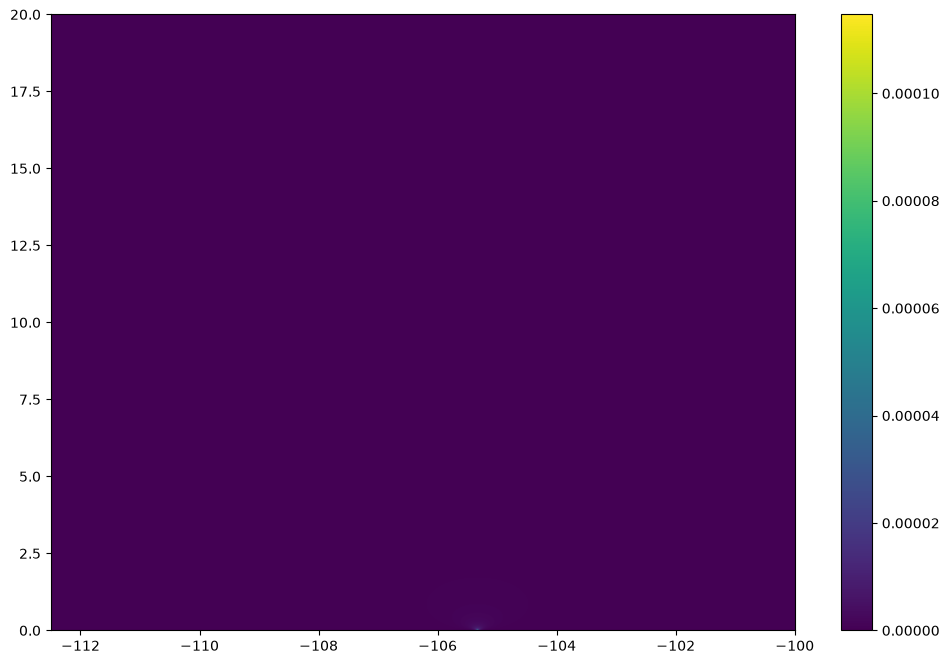

In [22]:
plt.imshow(posterior1, origin='lower', extent=(x_min, x_max, h_min, h_max), aspect='auto');
plt.colorbar();

but we can get a clearer picture using the `contour` and `contourf` functions

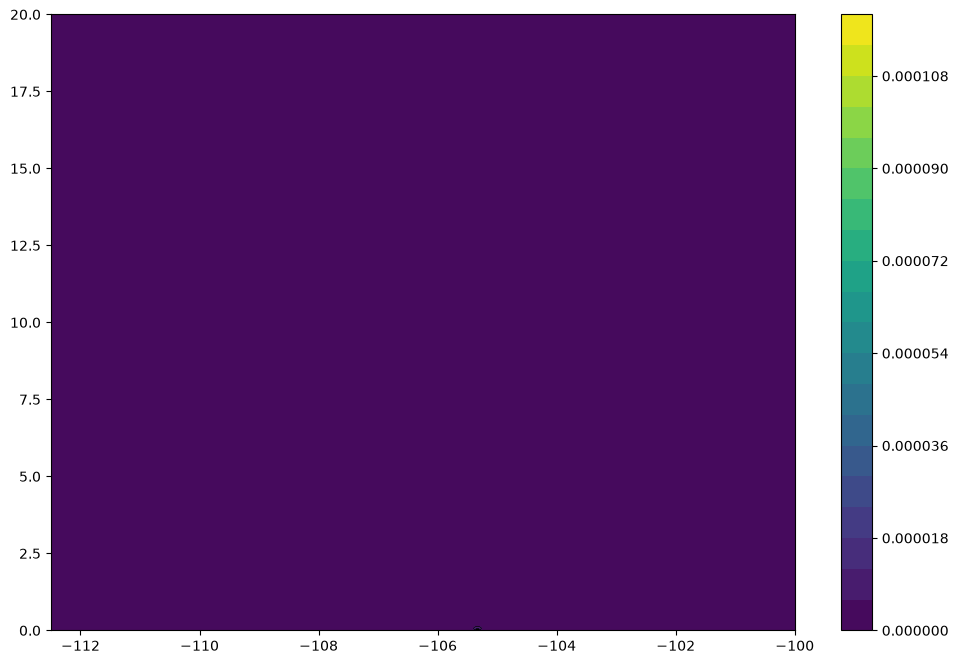

In [23]:
levels=20
cs = plt.contourf(x_lhs,hs, posterior1, levels=levels);
plt.contour(x_lhs,hs, posterior1, colors='black', linewidths=0.5, levels=levels);
plt.colorbar(cs);

Depending on the interval that you have chosen for the prior, you will probably not see  anything on the plots. This is OK as for one flash the distribution is strongly peaked around $(x_0,0)$. This will get better when we obtain more data.

#### MAP estimate

__Hint:__ Use the `numpy.argmax` and `numpy.unravel_index` functions.

In [24]:
max_idx = np.argmax(posterior1) 
j_max, i_max = np.unravel_index(max_idx, posterior1.shape)
x_lh_map = x_lhs[i_max]
h_map = hs[j_max]

print(f"Joint MAP estimate from one flash: x_lh = {x_lh_map:.3f}, h = {h_map:.3f}")

Joint MAP estimate from one flash: x_lh = -105.329, h = 0.007


### Marginal distributions

You can obtain the marginal distribution $p(x_{lh}|x_0)$ by summing the array along the axis zero.

Similarly the distribution $p(h|x_0)$ will be obtained by summing  over the axis one.

In [25]:
posterior_marg_x = posterior1.sum(axis=0)
posterior_marg_h = posterior1.sum(axis=1)
i_marg_x = np.argmax(posterior_marg_x)
x_lh_map_marg = x_lhs[i_marg_x]

# MAP for h marginal:
j_marg_h = np.argmax(posterior_marg_h)
h_map_marg = hs[j_marg_h]

print(f"Marginal MAP for x_lh = {x_lh_map_marg:.3f}")
print(f"Marginal MAP for h = {h_map_marg:.3f}")

Marginal MAP for x_lh = -105.329
Marginal MAP for h = 0.007


### Logarithms

More often than not we will be using logarithm of probabilities. Perform same calculations as previously, using the log of the probability.

In [26]:
log_prior_array = np.zeros_like(prior_array)

In [27]:
log_p_array = log_p(x_lh_grid, h_grid, flash_x[0])
log_posterior1= log_p_array+log_prior_array
Z= logsumexp(log_posterior1)
log_posterior1 -= Z

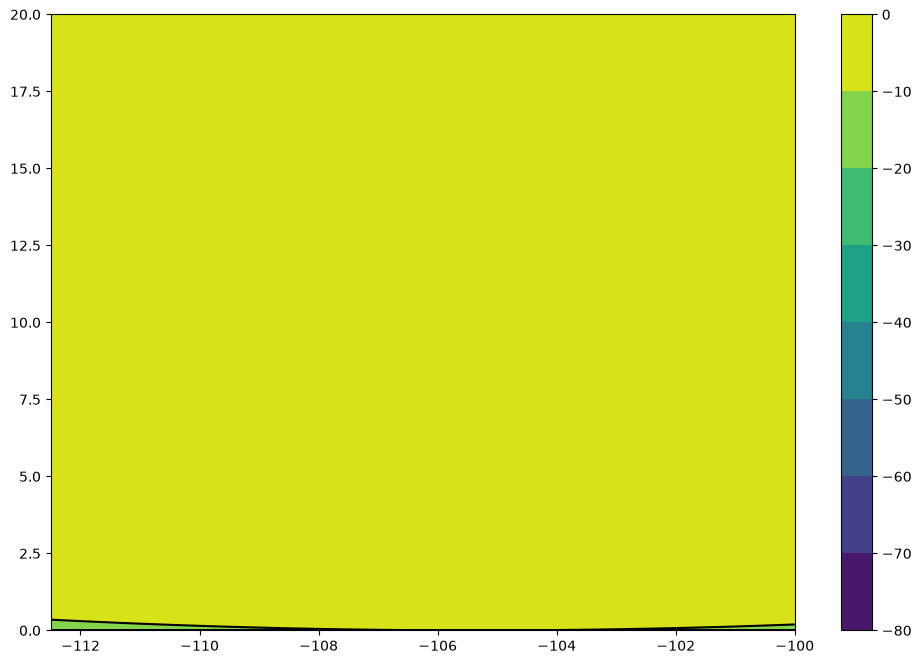

In [28]:
max_log_posterior = log_posterior1.max()
cs = plt.contourf(x_lhs,hs, log_posterior1-max_log_posterior);
plt.contour(x_lhs,hs, log_posterior1-max_log_posterior,colors = 'black', linestyles='-');
plt.colorbar(cs);

Because logarithm is a monotonically increasing function we can calculate the MAP estimate in the same way as for the  probabilities.

#### Marginal distributions

Again we have to partially sum the `log_posterior1` array. But before doing that we have to exponentiate it. To avoid numerical problems it is best to use the `scipy.special.logsumexp` function.

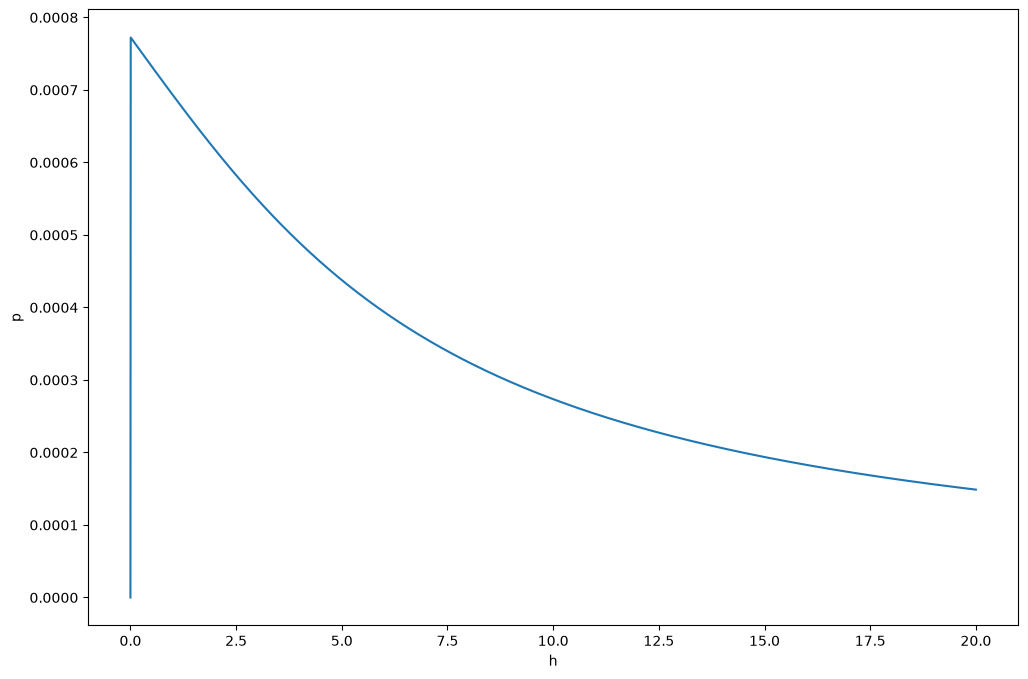

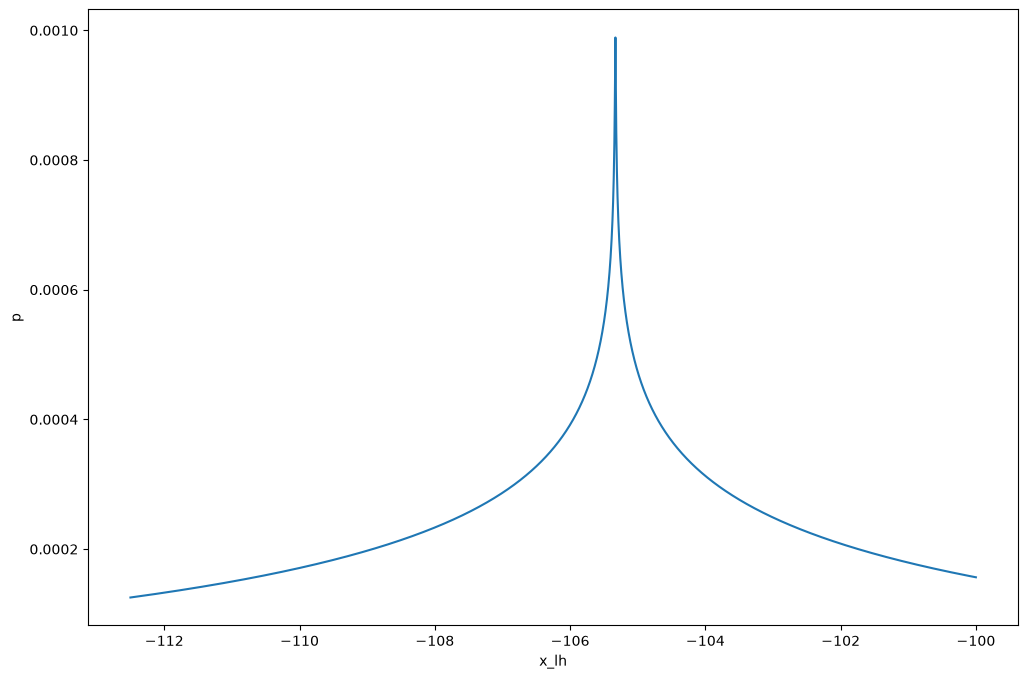

In [29]:
marg_x = posterior1.sum(axis=0)
marg_h = posterior1.sum(axis=1)  
plt.figure();   plt.plot(hs, marg_h);   plt.xlabel('h');  plt.ylabel('p');
plt.figure();   plt.plot(x_lhs, marg_x); plt.xlabel('x_lh'); plt.ylabel('p');

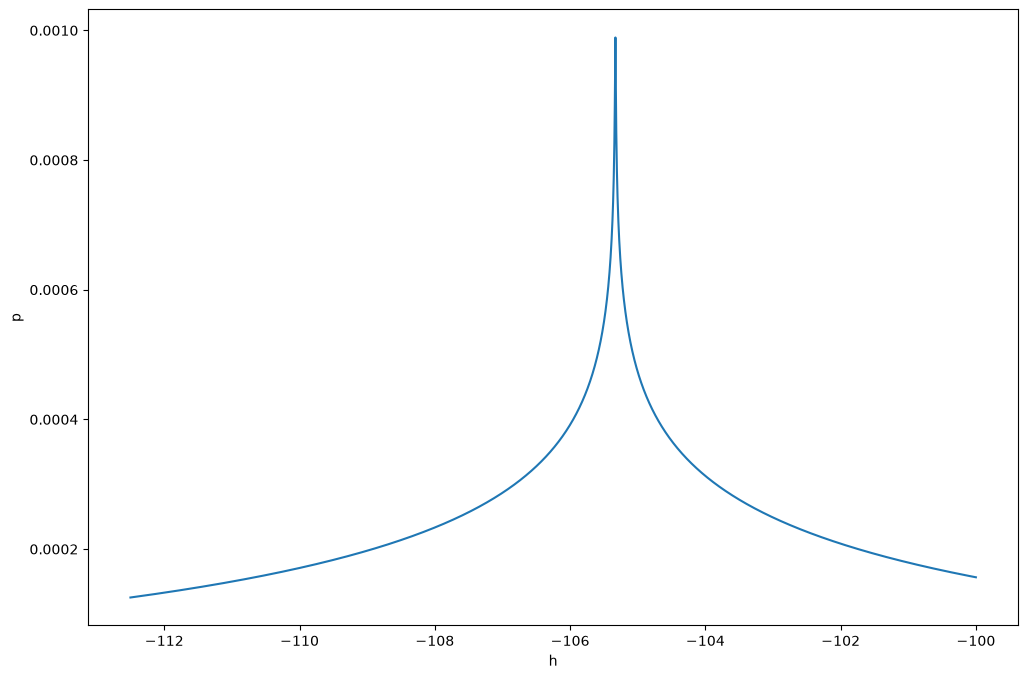

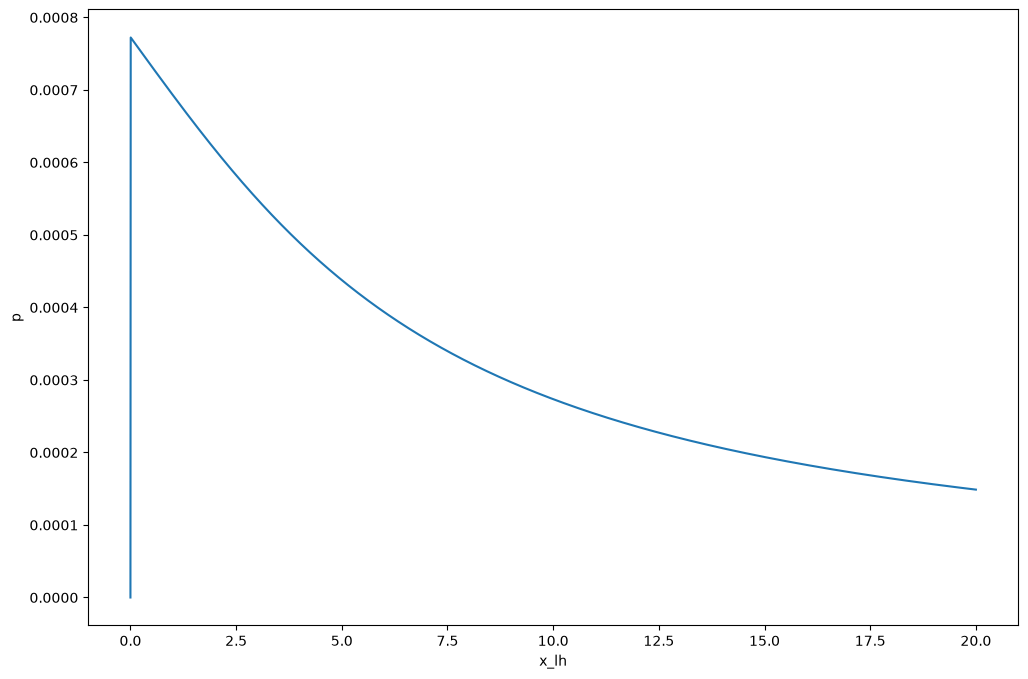

In [30]:
posterior_exp=np.exp(log_posterior1)

p_xlh_log=posterior_exp.sum(axis=0)
p_xlh_log/=p_xlh_log.sum()

p_h_log=posterior_exp.sum(axis=1)
p_h_log/=p_h_log.sum()
plt.plot(x_lhs, p_xlh_log);  plt.xlabel('h');  plt.ylabel('p');
plt.show()
plt.plot(hs, p_h_log);plt.xlabel('x_lh'); plt.ylabel('p');             

## Problem 3.1

Write down a function to compute an array containing the log of the sampling distribution using an array of flash positions, not just single point.

In [31]:
def log_p_many(x_lh, h, flashes):
    log_total = np.zeros_like(x_lh)
    for x in flashes:
        log_total += log_p(x_lh, h, x)
    return log_total

## Problem 3.2

Plot the (log)posterior distribution after two flashes. Calculate the MAP estimate, as well as the marginal distributions and MAP estimates for each variable separately.


=== Problem 3.2 with 2 flashes ===
Joint MAP => x_lh = -106.486, h = 1.247
Marginal MAP x_lh = -107.821, Marginal MAP h = 1.234


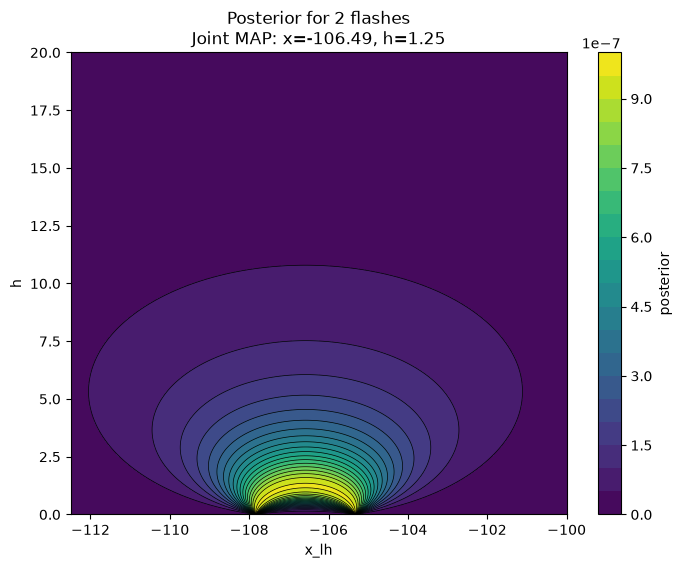

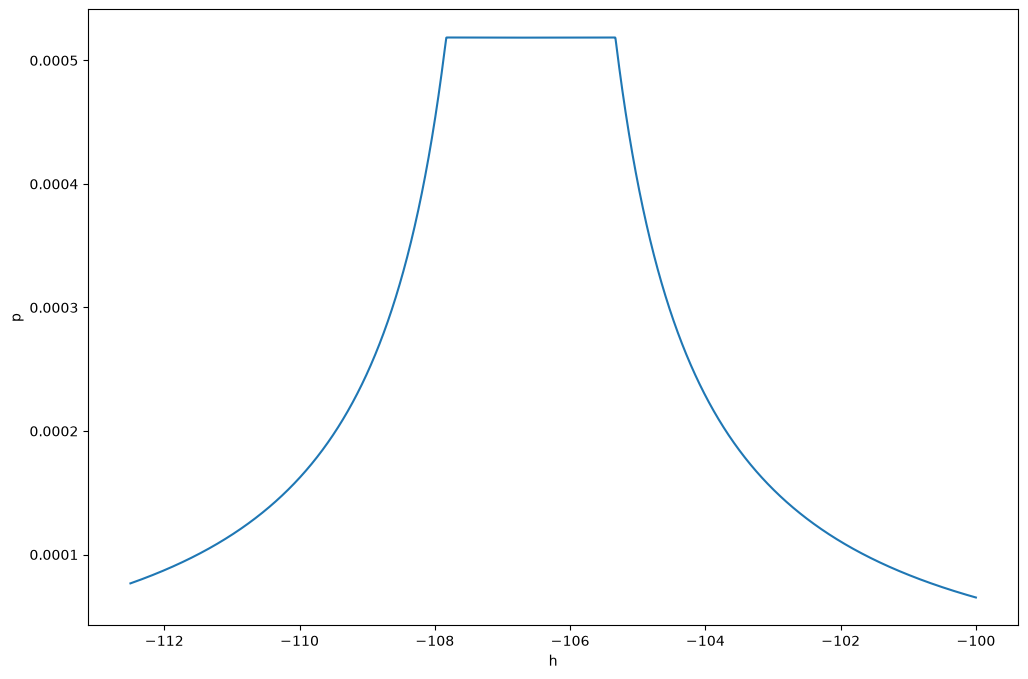

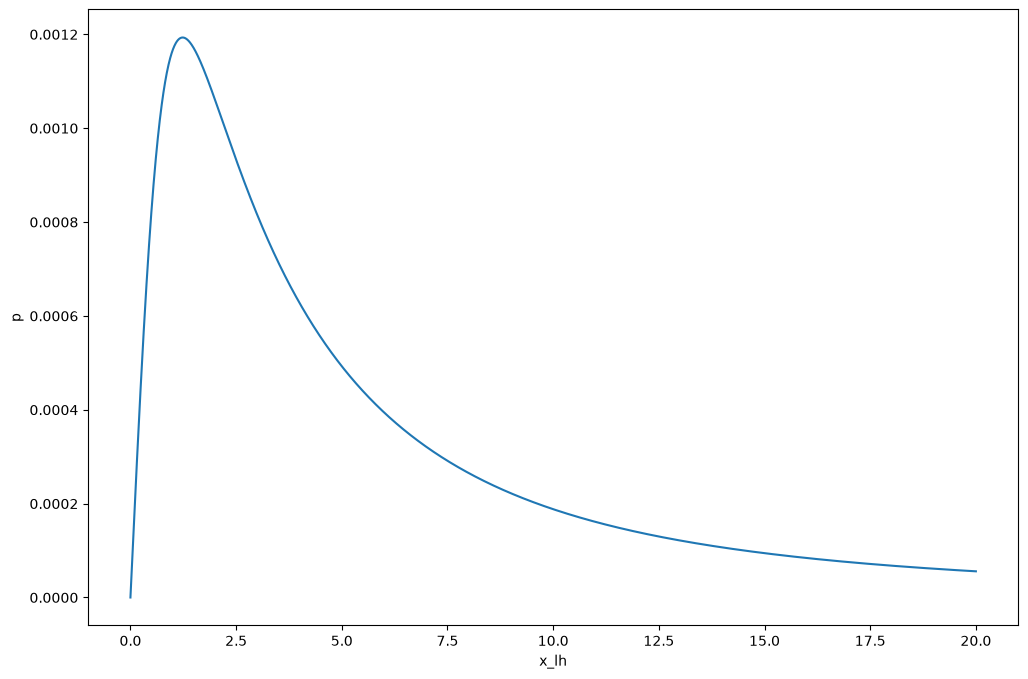

In [32]:
two_flashes = flash_x[:2]  

log_likelihood_2 = log_p_many(x_lh_grid, h_grid, two_flashes)

log_posterior_2 = log_likelihood_2 + log_prior_array

Z_2 = logsumexp(log_posterior_2)
log_posterior_2 -= Z_2

posterior_2 = np.exp(log_posterior_2)


idx_max_2 = np.argmax(posterior_2)
j_2, i_2 = np.unravel_index(idx_max_2, posterior_2.shape)
map_x_2 = x_lhs[i_2]
map_h_2 = hs[j_2]
print("\n=== Problem 3.2 with 2 flashes ===")
print(f"Joint MAP => x_lh = {map_x_2:.3f}, h = {map_h_2:.3f}")
marg_x_2 = posterior_2.sum(axis=0)  # sum over h
marg_h_2 = posterior_2.sum(axis=1)  # sum over x_lh
map_x_marg_2 = x_lhs[np.argmax(marg_x_2)]
map_h_marg_2 = hs[np.argmax(marg_h_2)]
print(f"Marginal MAP x_lh = {map_x_marg_2:.3f}, Marginal MAP h = {map_h_marg_2:.3f}")


plt.figure(figsize=(8, 6))
cs = plt.contourf(x_lhs, hs, posterior_2, levels=20)
plt.contour(x_lhs, hs, posterior_2, colors='black', linewidths=0.5, levels=20)
plt.xlabel('x_lh')
plt.ylabel('h')
plt.title(f'Posterior for 2 flashes\nJoint MAP: x={map_x_2:.2f}, h={map_h_2:.2f}')
plt.colorbar(cs, label='posterior')
plt.show()

plt.figure(); plt.plot(x_lhs, marg_x_2); plt.xlabel('h');  plt.ylabel('p');
plt.figure(); plt.plot(hs, marg_h_2); plt.xlabel('x_lh'); plt.ylabel('p'); 

## Problem 3.3

Perform same calculations as in the previous problem, but use all the flash positions.


=== Problem 3.3 with ALL flashes ===
Joint MAP => x_lh = -109.984, h = 2.848
Marginal MAP x_lh = -109.984, Marginal MAP h = 2.881


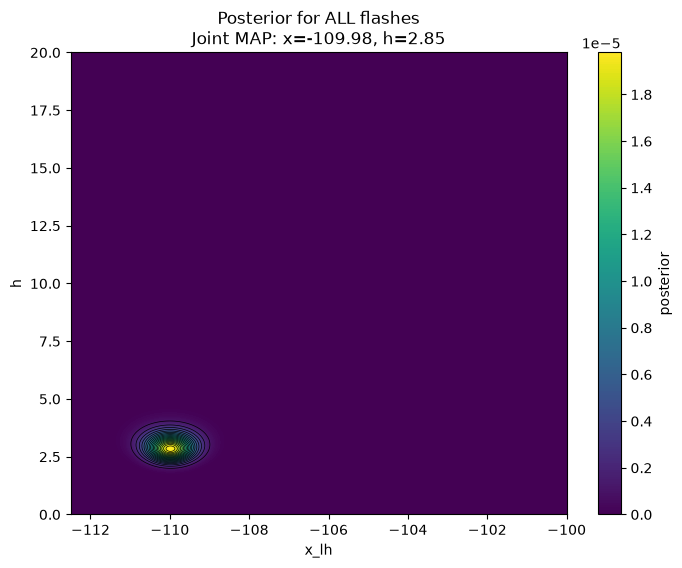

In [33]:
all_flashes = flash_x

log_likelihood_all = log_p_many(x_lh_grid, h_grid, all_flashes)
log_posterior_all = log_likelihood_all + log_prior_array

Z_all = logsumexp(log_posterior_all)
log_posterior_all -= Z_all

posterior_all = np.exp(log_posterior_all)

idx_max_all = np.argmax(posterior_all)
j_all, i_all = np.unravel_index(idx_max_all, posterior_all.shape)
map_x_all = x_lhs[i_all]
map_h_all = hs[j_all]
print("\n=== Problem 3.3 with ALL flashes ===")
print(f"Joint MAP => x_lh = {map_x_all:.3f}, h = {map_h_all:.3f}")

marg_x_all = posterior_all.sum(axis=0)  # sum over h
marg_h_all = posterior_all.sum(axis=1)  # sum over x_lh
map_x_marg_all = x_lhs[np.argmax(marg_x_all)]
map_h_marg_all = hs[np.argmax(marg_h_all)]
print(f"Marginal MAP x_lh = {map_x_marg_all:.3f}, Marginal MAP h = {map_h_marg_all:.3f}")

plt.figure(figsize=(8, 6))
cs = plt.contourf(x_lhs, hs, posterior_all, levels=200)
plt.contour(x_lhs, hs, posterior_all, colors='black', linewidths=0.5, levels=20)
plt.xlabel('x_lh')
plt.ylabel('h')
plt.title(f'Posterior for ALL flashes\nJoint MAP: x={map_x_all:.2f}, h={map_h_all:.2f}')
plt.colorbar(cs, label='posterior')
plt.show() 

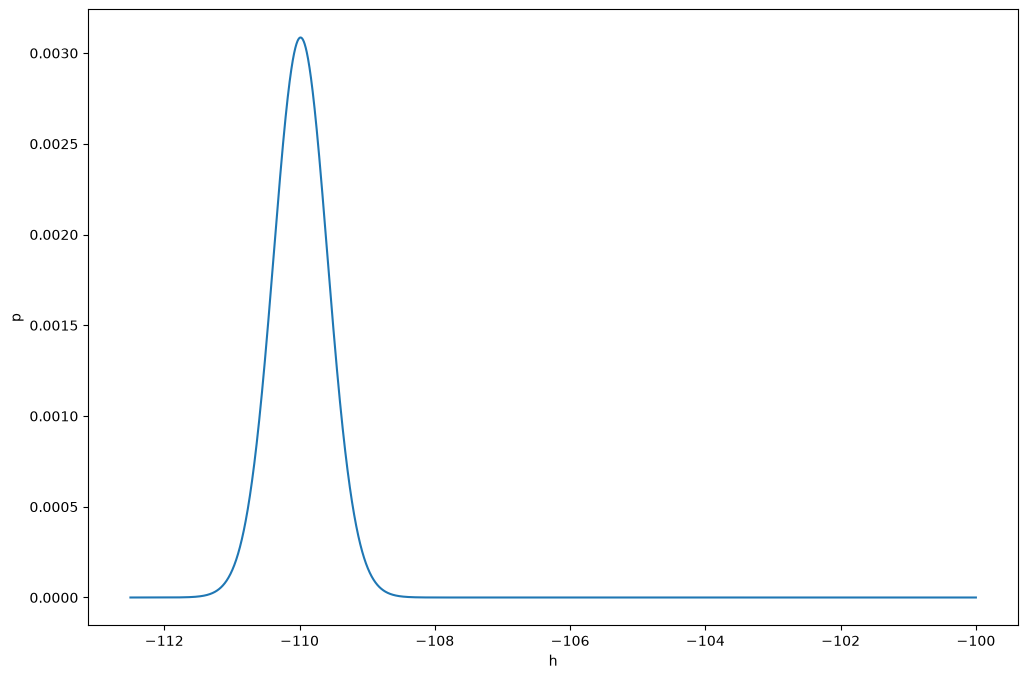

In [34]:
plt.figure(); plt.plot(x_lhs, marg_x_all); plt.xlabel('h');  plt.ylabel('p');

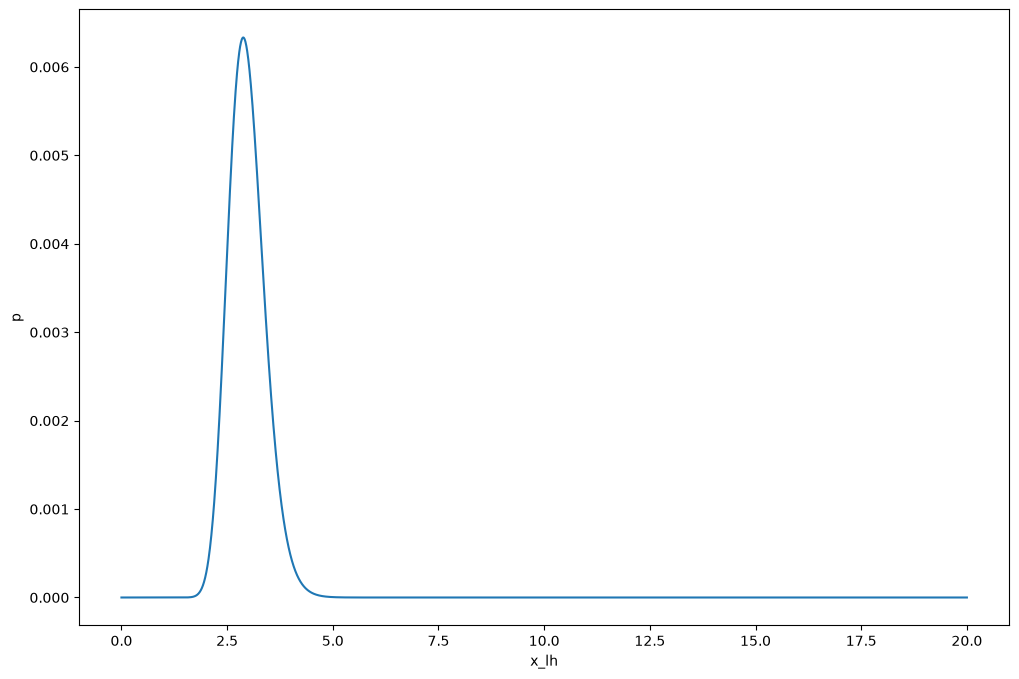

In [35]:
plt.figure(); plt.plot(hs, marg_h_all); plt.xlabel('x_lh'); plt.ylabel('p'); 